# STATS 201 Individual Research Proposal
## First-Operation Prediction in Financial Numerical Reasoning

**Research question.** How does training sample size affect the ability of multinomial logistic regression and random forests to predict the first operation in financial numerical reasoning programs for held-out companies?

This notebook compares a class-prior baseline, multinomial logistic regression and random forest using the same TF-IDF question features, training samples and fixed held-out-company test set.

The prediction target is the first operation in the reference program: `add`, `subtract`, `multiply` or `divide`. The experiment evaluates first-operation prediction only. It does not evaluate complete reasoning programs or final numerical answers.


## 1 · Research design

One observation is one financial question. The input feature is the question text in `input`. The target is the first operation extracted from the reference `program`.

Questions are grouped by company using the company identifier in `metadata.q_uid`. Entire companies are held out for testing, so a company cannot appear in both the training and test sets.

The test set remains fixed. The experiment compares three methods at 25%, 50% and 100% of the available training data:

1. Class-prior baseline
2. Multinomial logistic regression
3. Random forest

The two learning models use the same TF-IDF features and the same training rows at each budget. TF-IDF is fitted separately within each training budget.

The primary metric is multiclass log loss:

$$
L_m=-\frac{1}{|T|}\sum_{i\in T}\log \widehat p_m(y_i\mid x_i).
$$

Here, $T$ is the fixed held-out-company test set. Lower log loss is better. Accuracy is reported as a secondary metric.

### Experimental procedure

A fair comparison gives every method the same training rows, test rows and scoring rules at each training budget.

```text
Load the financial question-answering dataset
Extract the first operation from each reference program
Keep add, subtract, multiply and divide
Extract a company identifier from metadata.q_uid
Hold out entire companies as one fixed test set

FOR each training budget: 25%, 50% and 100%
    Select the training rows for that budget
    Fit TF-IDF using only those training questions
    Transform the fixed test questions

    FOR each method
        Fit the method on the same training rows
        Predict probabilities on the fixed test set
        Record log loss and accuracy
    END FOR
END FOR

Plot test log loss against the actual number of training rows
```

The class-prior baseline shows how well a method performs without using the question text.

In [22]:
%pip -q install datasets

import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from datasets import load_dataset
from huggingface_hub import HfApi
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import GroupShuffleSplit

## 2 · Prepare the financial question data

The source dataset is `orgrctera/uda_fin_qa_qa`. The main fields are `input`, `program` and `metadata`.

The label is the first function name in the reference program. This pilot keeps four labels: `add`, `subtract`, `multiply` and `divide`.

The company identifier is extracted from the first component of `metadata.q_uid`. For example, `ADI/2009/page_49.pdf-1` is assigned to company `ADI`.

The processed rows are divided into training companies and held-out test companies. The same test companies are used for every model and training budget.

In [23]:
DATASET_ID = "orgrctera/uda_fin_qa_qa"
RANDOM_STATE = 201

TARGET_OPERATIONS = {
    "add",
    "subtract",
    "multiply",
    "divide",
}

BUDGETS = [0.25, 0.50, 1.00]


api = HfApi()
dataset_info = api.dataset_info(DATASET_ID)
DATA_REVISION = dataset_info.sha

dataset = load_dataset(
    DATASET_ID,
    split="default",
    revision=DATA_REVISION,
)

df = dataset.to_pandas()


def parse_metadata(value):
    """Convert metadata into a Python dictionary."""
    if isinstance(value, dict):
        return value

    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return {}

    return {}


def extract_first_operation(program):
    """Return the first function name in the reference program."""
    if program is None:
        return None

    match = re.match(
        r"^\s*([A-Za-z_]+)\s*\(",
        str(program),
    )

    if match is None:
        return None

    return match.group(1).lower()


def extract_company_id(metadata):
    """Extract the company identifier from metadata.q_uid."""
    metadata_dict = parse_metadata(metadata)
    q_uid = metadata_dict.get("q_uid")

    if not q_uid:
        return None

    return str(q_uid).split("/")[0]


df["first_operation"] = df["program"].map(
    extract_first_operation
)

df["company_id"] = df["metadata"].map(
    extract_company_id
)


usable_mask = (
    df["input"].notna()
    & df["first_operation"].isin(TARGET_OPERATIONS)
    & df["company_id"].notna()
)

model_df = df.loc[usable_mask].copy()

model_df["input"] = (
    model_df["input"]
    .astype(str)
    .str.strip()
)

excluded_rows = len(df) - len(model_df)


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(
        model_df,
        groups=model_df["company_id"],
    )
)

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

train_companies = set(train_df["company_id"])
test_companies = set(test_df["company_id"])


print(f"Dataset: {DATASET_ID}")
print(f"Revision: {DATA_REVISION}")
print(f"Loaded rows: {len(df)}")
print(f"Fields: {dataset.column_names}")
print()

print(f"Usable pilot rows: {len(model_df)}")
print("Rows by first operation:")
print(model_df["first_operation"].value_counts())
print()

print(
    "Number of companies:",
    model_df["company_id"].nunique(),
)
print("Excluded rows:", excluded_rows)
print()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training companies:", len(train_companies))
print("Test companies:", len(test_companies))
print(
    "Company overlap:",
    len(train_companies & test_companies),
)
print()

print("Test labels:")
print(test_df["first_operation"].value_counts())
print()


classes = np.array(sorted(TARGET_OPERATIONS))

methods = {
    "Class prior": DummyClassifier(
        strategy="prior"
    ),

    "Logistic regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),

    "Random forest": RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}


records = []

for budget in BUDGETS:
    if budget < 1.0:
        budget_df = (
            train_df
            .groupby(
                "first_operation",
                group_keys=False,
            )
            .sample(
                frac=budget,
                random_state=RANDOM_STATE,
            )
        )
    else:
        budget_df = train_df.copy()

    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
    )

    X_train = vectorizer.fit_transform(
        budget_df["input"]
    )

    X_test = vectorizer.transform(
        test_df["input"]
    )

    y_train = budget_df[
        "first_operation"
    ].to_numpy()

    y_test = test_df[
        "first_operation"
    ].to_numpy()

    for method_name, model in methods.items():

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)

        aligned_probabilities = np.zeros(
            (
                len(y_test),
                len(classes),
            )
        )

        for model_column, class_name in enumerate(
            model.classes_
        ):
            target_column = np.where(
                classes == class_name
            )[0][0]

            aligned_probabilities[
                :,
                target_column
            ] = probabilities[:, model_column]

        probabilities = aligned_probabilities

        records.append(
            {
                "Budget": budget,
                "Train rows": len(budget_df),
                "Method": method_name,
                "Log Loss": log_loss(
                    y_test,
                    probabilities,
                    labels=classes,
                ),
                "Accuracy": accuracy_score(
                    y_test,
                    predictions,
                ),
            }
        )



results = pd.DataFrame(records)

display(
    results.style.format(
        {
            "Budget": "{:.0%}",
            "Log Loss": "{:.4f}",
            "Accuracy": "{:.4f}",
        }
    )
)

Dataset: orgrctera/uda_fin_qa_qa
Revision: e3fd7b0cde4cf1dafb49f03528f0f9f8275fcd1f
Loaded rows: 8190
Fields: ['input', 'metadata', 'answers', 'evidence', 'context', 'program']

Usable pilot rows: 7788
Rows by first operation:
first_operation
subtract    3170
divide      3012
add         1127
multiply     479
Name: count, dtype: int64

Number of companies: 137
Excluded rows: 402

Training rows: 6168
Test rows: 1620
Training companies: 109
Test companies: 28
Company overlap: 0

Test labels:
first_operation
divide      686
subtract    607
add         211
multiply    116
Name: count, dtype: int64



,Budget,Train rows,Method,Log Loss,Accuracy
0,25%,1543,Class prior,1.1932,0.3747
1,25%,1543,Logistic regression,0.6832,0.7784
2,25%,1543,Random forest,0.7211,0.7932
3,50%,3085,Class prior,1.1932,0.3747
4,50%,3085,Logistic regression,0.6299,0.8006
5,50%,3085,Random forest,0.7156,0.7994
6,100%,6168,Class prior,1.1933,0.3747
7,100%,6168,Logistic regression,0.5933,0.8086
8,100%,6168,Random forest,0.7316,0.8062


### Read the data and model results

The printed data summary reports the dataset revision, number of usable questions, excluded rows, class counts, number of companies and company-level split.

The results table reports test Log Loss and Accuracy for each model at each training budget.

Log Loss evaluates the probabilities assigned to the observed classes. Lower values are better. Accuracy reports the proportion of correct predicted labels. Higher values are better.

All methods are evaluated on the same fixed held-out-company test set.

## 3 · Compare learning curves

The learning curve compares the three methods on the same fixed held-out-company test set.

The horizontal axis is the actual number of training questions. The vertical axis is test Log Loss. Lower values indicate better probabilistic predictions.

A model is more sample-efficient if it achieves lower test Log Loss with fewer training questions.

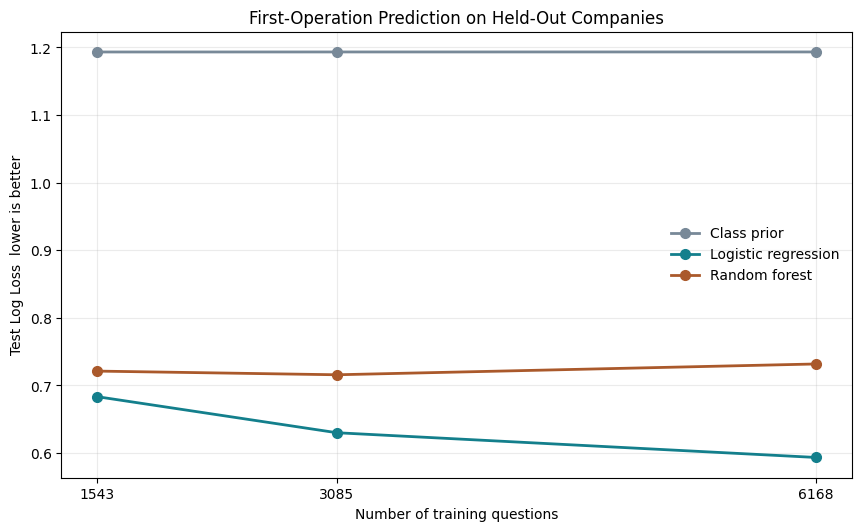

In [24]:
colors = {
    "Class prior": "#788998",
    "Logistic regression": "#137f8c",
    "Random forest": "#aa592b"
}

fig, ax = plt.subplots(
    figsize=(8.5, 5.2),
    layout="constrained"
)

for method_name, method_results in results.groupby(
    "Method"
):
    method_results = method_results.sort_values(
        "Train rows"
    )

    ax.plot(
        method_results["Train rows"],
        method_results["Log Loss"],
        marker="o",
        linewidth=2,
        markersize=7,
        color=colors[method_name],
        label=method_name
    )

ax.set_title(
    "First-Operation Prediction on Held-Out Companies"
)

ax.set_xlabel(
    "Number of training questions"
)

ax.set_ylabel(
    "Test Log Loss  lower is better"
)

ax.set_xticks(
    sorted(results["Train rows"].unique())
)

ax.grid(alpha=0.25)
ax.legend(frameon=False)

plt.show()

### Interpret the learning curve

Use the actual output above to answer:

1. Which method has the lowest Log Loss at 25% of the training data?
2. Does each model improve as the number of training questions increases?
3. Which model shows the largest improvement between 25% and 100%?
4. Do the learning models outperform the class-prior baseline?
5. Are the conclusions limited to the fixed held-out companies?

Do not complete this interpretation until the experiment has been run.

## Conclusions and limitations

**Result.** Complete this section after running the experiment. Report which model achieved the lowest held-out-company Log Loss at each training budget.

**Interpretation.** Explain whether increasing the number of training questions improved probabilistic prediction for logistic regression and random forest.

**Measurement limitation.** The label is the first operation in one reference program. An equivalent solution may use a different valid operation order.

**Generalization limitation.** The results describe first-operation prediction for the fixed held-out companies. They do not measure complete program generation or final numerical-answer accuracy.

**Practical consequence.** A consequential error occurs when a question that should first calculate a difference is predicted as direct division. This could skip the change calculation required for a growth-rate or percentage-change question.

## 4 · Outputs for the research proposal

This notebook produces:

1. A processed four-class first-operation dataset
2. A fixed company-level train and test split
3. Results for the class-prior baseline, logistic regression and random forest
4. Log Loss and Accuracy at 25%, 50% and 100% training budgets
5. A learning curve for the fixed held-out-company test set

The final proposal should report the exact Hugging Face dataset revision and GitHub code commit used to produce these results.

In [25]:
import numpy as np
from sklearn.metrics import log_loss

EXPECTED_CLASSES = sorted(TARGET_OPERATIONS)

print("Expected class order:", EXPECTED_CLASSES)
print()



print("=== Training-budget class coverage ===")

for budget in BUDGETS:
    train_n = int(
        results.loc[
            results["Budget"].eq(budget),
            "Train rows"
        ].iloc[0]
    )

    if train_n == len(train_df):
        check_df = train_df.copy()
    else:
        check_df = train_df.sample(
            n=train_n,
            random_state=RANDOM_STATE
        )

    observed_classes = sorted(
        check_df["first_operation"].unique()
    )

    missing_classes = sorted(
        set(EXPECTED_CLASSES) - set(observed_classes)
    )

    print(
        f"{budget:.0%}: "
        f"n={train_n}, "
        f"classes={observed_classes}"
    )

    assert not missing_classes, (
        f"{budget:.0%} training budget is missing: "
        f"{missing_classes}"
    )


test_classes = sorted(
    test_df["first_operation"].unique()
)

test_missing = sorted(
    set(EXPECTED_CLASSES) - set(test_classes)
)

print(
    f"Test set: "
    f"n={len(test_df)}, "
    f"classes={test_classes}"
)

assert not test_missing, (
    f"Test set is missing: {test_missing}"
)

print("All training budgets and the test set cover four classes.")
print()



print("=== Model class order ===")

for name, fitted_model in methods.items():
    model_classes = list(fitted_model.classes_)

    print(f"{name}: {model_classes}")

    assert set(model_classes) == set(EXPECTED_CLASSES), (
        f"{name} does not contain the expected four classes."
    )

print("All fitted models contain the expected four classes.")
print()



print("=== Current predict_proba check ===")

model_classes = list(model.classes_)

print("Current model:", type(model).__name__)
print("model.classes_:", model_classes)
print("probabilities shape:", probabilities.shape)

assert probabilities.shape[1] == len(model_classes), (
    "The number of probability columns does not match "
    "the number of model classes."
)

column_indices = [
    model_classes.index(label)
    for label in EXPECTED_CLASSES
]

aligned_probabilities = probabilities[:, column_indices]

assert np.allclose(
    aligned_probabilities.sum(axis=1),
    1.0,
    atol=1e-6
), "Some probability rows do not sum to 1."

checked_log_loss = log_loss(
    y_test,
    aligned_probabilities,
    labels=EXPECTED_CLASSES
)

recorded_log_loss = float(
    results.loc[
        results["Budget"].eq(1.0)
        & results["Method"].eq("Random forest"),
        "Log Loss"
    ].iloc[0]
)

print("Aligned class order:", EXPECTED_CLASSES)
print(f"Recalculated Log Loss: {checked_log_loss:.6f}")
print(f"Recorded Log Loss:     {recorded_log_loss:.6f}")

assert np.isclose(
    checked_log_loss,
    recorded_log_loss,
    atol=1e-10
), (
    "The recalculated Log Loss does not match "
    "the recorded Random Forest result."
)

print()
print("All checks passed.")

Expected class order: ['add', 'divide', 'multiply', 'subtract']

=== Training-budget class coverage ===
25%: n=1543, classes=['add', 'divide', 'multiply', 'subtract']
50%: n=3085, classes=['add', 'divide', 'multiply', 'subtract']
100%: n=6168, classes=['add', 'divide', 'multiply', 'subtract']
Test set: n=1620, classes=['add', 'divide', 'multiply', 'subtract']
All training budgets and the test set cover four classes.

=== Model class order ===
Class prior: ['add', 'divide', 'multiply', 'subtract']
Logistic regression: ['add', 'divide', 'multiply', 'subtract']
Random forest: ['add', 'divide', 'multiply', 'subtract']
All fitted models contain the expected four classes.

=== Current predict_proba check ===
Current model: RandomForestClassifier
model.classes_: ['add', 'divide', 'multiply', 'subtract']
probabilities shape: (1620, 4)
Aligned class order: ['add', 'divide', 'multiply', 'subtract']
Recalculated Log Loss: 0.731610
Recorded Log Loss:     0.731610

All checks passed.


In [27]:
import json
from google.colab import files

release_df = model_df.copy()

def extract_metadata(metadata, key):
    if isinstance(metadata, str):
        metadata = json.loads(metadata)
    return metadata.get(key)

# Extract identifiers
release_df["q_uid"] = release_df["metadata"].apply(
    lambda x: extract_metadata(x, "q_uid")
)

release_df["label_key"] = release_df["metadata"].apply(
    lambda x: extract_metadata(x, "label_key")
)

# Extract company from q_uid, such as ADI/2009/... → ADI
release_df["company"] = release_df["q_uid"].str.split("/").str[0]

# Add the fixed experimental split
release_df["split"] = "train"
release_df.loc[test_df.index, "split"] = "test"

# Keep release columns
release_df = release_df[
    [
        "q_uid",
        "label_key",
        "company",
        "input",
        "program",
        "first_operation",
        "split"
    ]
].copy()

# Check the exported data
assert len(release_df) == 7788
assert (release_df["split"] == "train").sum() == 6168
assert (release_df["split"] == "test").sum() == 1620
assert set(release_df["first_operation"]) == {
    "add", "subtract", "multiply", "divide"
}
assert release_df.isna().sum().sum() == 0

# Export and download
output_file = "qingyue-colab.csv"
release_df.to_csv(output_file, index=False)

print("Created:", output_file)
print("Rows:", len(release_df))
print("\nSplit counts:")
print(release_df["split"].value_counts())
print("\nOperation counts:")
print(release_df["first_operation"].value_counts())

files.download(output_file)

Created: qingyue-colab.csv
Rows: 7788

Split counts:
split
train    6168
test     1620
Name: count, dtype: int64

Operation counts:
first_operation
subtract    3170
divide      3012
add         1127
multiply     479
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>